--- TOP 5 LÍDERES CON BETA DE TRANSMISIÓN Y R2: ÉPOCA 2 (SELL) ---


,Vendedor,Lag_Stackelberg,P_Stackelberg,Beta_PassThrough,R2_Predictivo,Reacciona_al_Mercado
21,FastG0ZU,4,6.304906e-13,1.064319,0.427596,False
22,GermanBol,2,3.072714e-07,0.237622,0.188696,True
23,MegaCrypToE,2,3.873697e-07,0.607523,0.218205,False
24,Te_Gateo,2,6.604420e-07,0.238803,0.188934,True
25,_FastCoins_,3,1.735032e-06,0.852082,0.191092,False



--- TOP 5 LÍDERES CON BETA DE TRANSMISIÓN Y R2: ÉPOCA 2 (BUY) ---


,Vendedor,Lag_Stackelberg,P_Stackelberg,Beta_PassThrough,R2_Predictivo,Reacciona_al_Mercado
70,P2P-AJAG,2,3.597874e-08,0.844976,0.232868,True
71,issei300,2,2.335775e-05,0.351744,0.135875,True
72,GermanBol,2,7.129772e-05,0.629188,0.162804,True
73,_FastCoins_,2,8.229990e-05,0.481361,0.123760,True
74,Lion_Liquidity,4,1.023330e-04,0.292834,0.146615,True


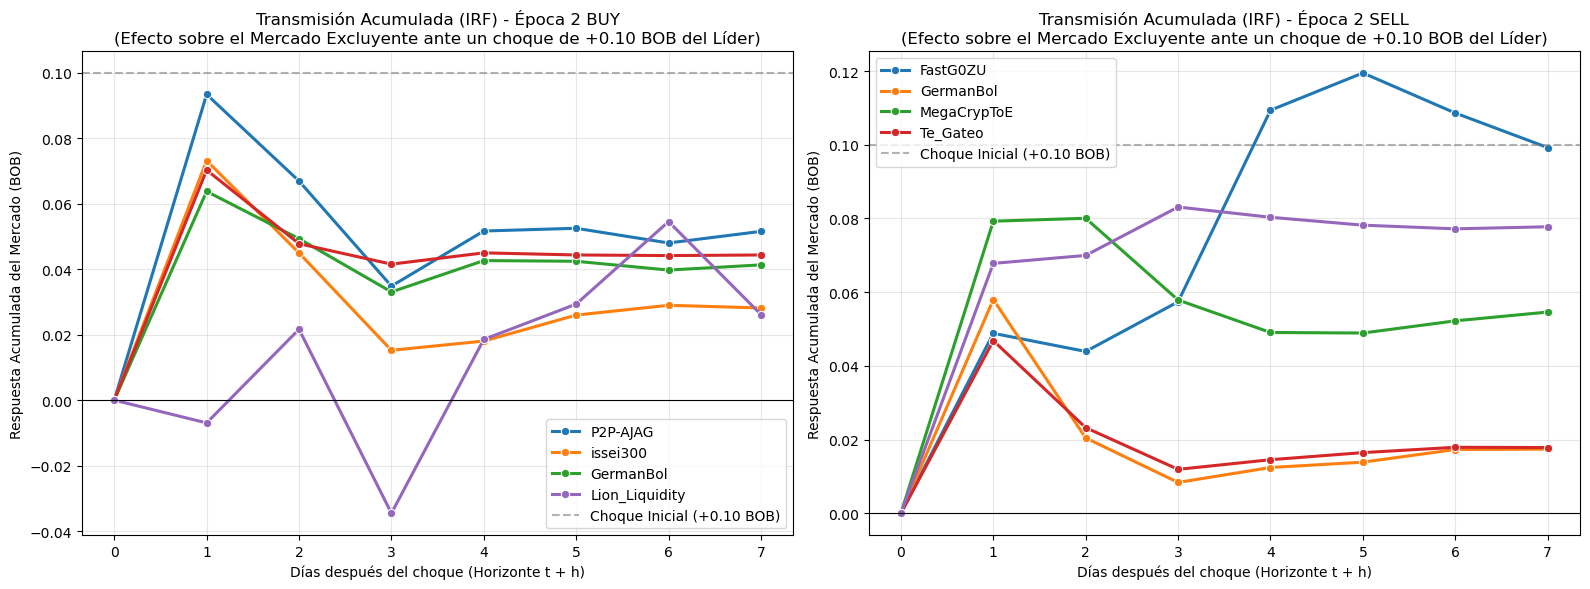

In [1]:
# ============================================================
# LABORATORIO DE COMPETENCIA Y MICROESTRUCTURA DEL MERCADO P2P
# Notebook 03: Modelo VAR, Impulso-Respuesta (IRF) y Determinantes de Microestructura
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

ruta_clean = Path("../data_clean")
ranking_total = pd.read_csv(ruta_clean / "resultados_granger_stackelberg_bertrand.csv")

def estimar_passthrough_e_irf(horizonte=7):
    """
    1. Calcula el coeficiente Beta de transmisión acumulada y el R2 predictivo para cada vendedor.
    2. Estima un modelo VAR Bivariado [Líder, Mercado_Excluyente] para el Top 10 de la Época 2
       y simula la Función de Impulso-Respuesta (IRF) ante un choque de +0.10 BOB.
    """
    betas = []
    R2s = []
    irf_registros = []
    
    # Cargar matrices por bloque
    cache_vwap = {}
    cache_excl = {}
    for ep in [1, 2]:
        for t in ['sell', 'buy']:
            b_nom = f"Epoca{ep}_{t.upper()}"
            cache_vwap[b_nom] = pd.read_csv(ruta_clean / f"vwap_diario_epoca{ep}_{t}.csv", index_col=0, parse_dates=True).diff().dropna()
            cache_excl[b_nom] = pd.read_csv(ruta_clean / f"mercado_excl_epoca{ep}_{t}.csv", index_col=0, parse_dates=True).diff().dropna()

    for idx, fila in ranking_total.iterrows():
        b_nom = fila['Bloque']
        vend = fila['Vendedor']
        lag_opt = int(fila['Lag_Stackelberg'])
        
        s_vend = cache_vwap[b_nom][vend]
        s_merc = cache_excl[b_nom][vend]
        data_stack = pd.concat([s_merc, s_vend], axis=1).dropna()
        
        try:
            test = grangercausalitytests(data_stack, maxlag=lag_opt, verbose=False)
            ols_unrest = test[lag_opt][1][1]
            r2_val = float(ols_unrest.rsquared)
            # Suma de los coeficientes rezagados del vendedor sobre el mercado excluyente
            beta_val = float(np.sum(ols_unrest.params[lag_opt : 2 * lag_opt]))
        except Exception:
            beta_val, r2_val = 0.0, 0.0
            
        betas.append(beta_val)
        R2s.append(r2_val)
        
        # Simular IRF mediante VAR Bivariado para los líderes de la Época 2
        if b_nom in ['Epoca2_BUY', 'Epoca2_SELL']:
            data_var = pd.concat([s_vend.rename('Lider'), s_merc.rename('Mercado')], axis=1).dropna()
            try:
                modelo_var = VAR(data_var)
                res_var = modelo_var.fit(lag_opt)
                irf = res_var.irf(horizonte)
                
                # Impulso de +0.10 BOB en el Líder (índice 0) -> Respuesta en el Mercado Excluyente (índice 1)
                resp_diaria = irf.irfs[:, 1, 0] * 0.10
                resp_acum = np.cumsum(resp_diaria)
                
                for h in range(horizonte + 1):
                    irf_registros.append({
                        'Bloque': b_nom,
                        'Vendedor': vend,
                        'Dia_Horizonte': h,
                        'Respuesta_Diaria_BOB': float(resp_diaria[h]),
                        'Respuesta_Acumulada_BOB': float(resp_acum[h])
                    })
            except Exception:
                continue

    ranking_total['Beta_PassThrough'] = betas
    ranking_total['R2_Predictivo'] = R2s
    df_irf = pd.DataFrame(irf_registros)
    return ranking_total, df_irf

ranking_enriquecido, df_irf_epoca2 = estimar_passthrough_e_irf(horizonte=7)

# Actualizar el archivo maestro para Streamlit Cloud con Beta y R2
ranking_enriquecido.to_csv(ruta_clean / "resultados_granger_stackelberg_bertrand.csv", index=False)
df_irf_epoca2.to_csv(ruta_clean / "irf_var_epoca2.csv", index=False)

print("--- TOP 5 LÍDERES CON BETA DE TRANSMISIÓN Y R2: ÉPOCA 2 (SELL) ---")
display(ranking_enriquecido[ranking_enriquecido['Bloque'] == 'Epoca2_SELL'][
    ['Vendedor', 'Lag_Stackelberg', 'P_Stackelberg', 'Beta_PassThrough', 'R2_Predictivo', 'Reacciona_al_Mercado']
].head(5))

print("\n--- TOP 5 LÍDERES CON BETA DE TRANSMISIÓN Y R2: ÉPOCA 2 (BUY) ---")
display(ranking_enriquecido[ranking_enriquecido['Bloque'] == 'Epoca2_BUY'][
    ['Vendedor', 'Lag_Stackelberg', 'P_Stackelberg', 'Beta_PassThrough', 'R2_Predictivo', 'Reacciona_al_Mercado']
].head(5))

# Graficar Funciones de Impulso-Respuesta Acumuladas (Top 5 Líderes en BUY y SELL)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, bloque, titulo in zip(
    axes, 
    ['Epoca2_BUY', 'Epoca2_SELL'], 
    ['Transmisión Acumulada (IRF) - Época 2 BUY', 'Transmisión Acumulada (IRF) - Época 2 SELL']
):
    top5_v = ranking_enriquecido[
        (ranking_enriquecido['Bloque'] == bloque) & 
        (ranking_enriquecido['Dias_Cambio_Precio'] >= 30)
    ].head(5)['Vendedor'].tolist()
    
    sub_irf = df_irf_epoca2[(df_irf_epoca2['Bloque'] == bloque) & (df_irf_epoca2['Vendedor'].isin(top5_v))]
    sns.lineplot(data=sub_irf, x='Dia_Horizonte', y='Respuesta_Acumulada_BOB', hue='Vendedor', marker='o', linewidth=2.2, ax=ax)
    ax.axhline(0.10, color='gray', linestyle='--', alpha=0.6, label='Choque Inicial (+0.10 BOB)')
    ax.axhline(0.0, color='black', linewidth=0.8)
    ax.set_title(f"{titulo}\n(Efecto sobre el Mercado Excluyente ante un choque de +0.10 BOB del Líder)")
    ax.set_xlabel("Días después del choque (Horizonte t + h)")
    ax.set_ylabel("Respuesta Acumulada del Mercado (BOB)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [2]:
# ============================================================
# 2. VAR MULTIVARIADO Y DESCOMPOSICIÓN DE LA VARIANZA (FEVD)
# ============================================================

def estimar_fevd_multivariado(tipo_orden, epoca_num=2, top_n=5, lags_var=2, horizonte=7):
    """
    Estima un sistema VAR conjunto entre los Top 5 líderes para cuantificar
    qué porcentaje de la varianza de precios de cada líder proviene de sus propios
    choques vs. el contagio de sus competidores directos (FEVD a 7 días).
    """
    b_nom = f"Epoca{epoca_num}_{tipo_orden.upper()}"
    df_vwap = pd.read_csv(ruta_clean / f"vwap_diario_epoca{epoca_num}_{tipo_orden.lower()}.csv", index_col=0, parse_dates=True)
    
    top_v = ranking_enriquecido[
        (ranking_enriquecido['Bloque'] == b_nom) & 
        (ranking_enriquecido['Dias_Cambio_Precio'] >= 30)
    ].head(top_n)['Vendedor'].tolist()
    
    d_top = df_vwap[top_v].diff().dropna()
    modelo = VAR(d_top)
    res = modelo.fit(lags_var)
    fevd = res.fevd(horizonte)
    
    # Extraer la descomposición en el horizonte final (día 7)
    # fevd.decomp tiene forma (variables, horizonte, choques)
    matriz_fevd = pd.DataFrame(
        fevd.decomp[:, -1, :] * 100, 
        index=top_v, 
        columns=top_v
    )
    matriz_fevd['Contagio_de_Competidores_Pct'] = 100.0 - np.diag(matriz_fevd)
    return matriz_fevd, res.is_stable()

fevd_buy2, estable_buy = estimar_fevd_multivariado('buy', 2)
fevd_sell2, estable_sell = estimar_fevd_multivariado('sell', 2)

print(f"--- DESCOMPOSICIÓN DE VARIANZA (FEVD A 7 DÍAS, EN %) - ÉPOCA 2 BUY (VAR Estable: {estable_buy}) ---")
display(fevd_buy2.round(2))

print(f"\n--- DESCOMPOSICIÓN DE VARIANZA (FEVD A 7 DÍAS, EN %) - ÉPOCA 2 SELL (VAR Estable: {estable_sell}) ---")
display(fevd_sell2.round(2))

fevd_buy2.to_csv(ruta_clean / "fevd_multivariado_epoca2_buy.csv")
fevd_sell2.to_csv(ruta_clean / "fevd_multivariado_epoca2_sell.csv")

--- DESCOMPOSICIÓN DE VARIANZA (FEVD A 7 DÍAS, EN %) - ÉPOCA 2 BUY (VAR Estable: True) ---


,P2P-AJAG,issei300,GermanBol,_FastCoins_,Lion_Liquidity,Contagio_de_Competidores_Pct
P2P-AJAG,74.52,4.73,5.53,4.30,10.92,25.48
issei300,53.02,31.78,5.87,3.06,6.26,68.22
GermanBol,49.09,9.75,34.78,3.59,2.80,65.22
_FastCoins_,54.53,5.53,7.85,29.07,3.03,70.93
Lion_Liquidity,34.10,11.58,1.19,4.47,48.66,51.34



--- DESCOMPOSICIÓN DE VARIANZA (FEVD A 7 DÍAS, EN %) - ÉPOCA 2 SELL (VAR Estable: True) ---


,FastG0ZU,GermanBol,MegaCrypToE,Te_Gateo,_FastCoins_,Contagio_de_Competidores_Pct
FastG0ZU,76.84,2.82,14.93,3.36,2.05,23.16
GermanBol,44.12,25.64,24.05,3.18,3.01,74.36
MegaCrypToE,46.64,21.21,24.19,4.21,3.75,75.81
Te_Gateo,36.13,17.25,18.13,26.14,2.36,73.86
_FastCoins_,39.83,15.15,21.43,2.81,20.77,79.23


In [3]:
# ============================================================
# 3. DETERMINANTES MICROECONÓMICOS DEL LIDERAZGO DE PRECIOS
# ============================================================

# Ruta al CSV original (misma ruta utilizada en tu Notebook 01)
archivo_raw = Path("../../Dashboard-Economico2/data/detalle_binance3.csv")
if not archivo_raw.exists():
    archivo_raw = Path("../Dashboard-Economico2/data/detalle_binance3.csv")

df_raw = pd.read_csv(archivo_raw, sep=";", encoding="utf-8")
df_raw['Timestamp'] = pd.to_datetime(df_raw['Timestamp'], dayfirst=True, errors='coerce')
for col in ['Precio', 'Limite_min', 'Limite_max', 'Disponible']:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')
df_raw = df_raw.dropna(subset=['Timestamp', 'Precio', 'Disponible'])
df_raw['Fecha'] = pd.to_datetime(df_raw['Timestamp'].dt.date)

def extraer_perfil_microestructura(df_r, fecha_ini, fecha_fin, tipo_orden, nombre_bloque):
    sub = df_r[(df_r['Tipo'] == tipo_orden) & (df_r['Fecha'] >= fecha_ini) & (df_r['Fecha'] <= fecha_fin)].copy()
    
    # Número de anuncios simultáneos por snapshot (estrategia multi-anuncio)
    ads_snap = sub.groupby(['Vendedor', 'Timestamp']).size().reset_index(name='N_Ads_Snap')
    multi_ad = ads_snap.groupby('Vendedor').agg(
        Anuncios_Por_Snapshot=('N_Ads_Snap', 'mean'),
        Pct_Snapshots_MultiAnuncio=('N_Ads_Snap', lambda x: (x > 1).mean() * 100)
    )
    
    perfil = sub.groupby('Vendedor').agg(
        Snapshots_Presente=('Timestamp', 'nunique'),
        Disponibilidad_Media_USDT=('Disponible', 'mean'),
        Limite_Min_Medio_BOB=('Limite_min', 'mean'),
        Limite_Max_Medio_BOB=('Limite_max', 'mean')
    ).join(multi_ad)
    
    perfil['Bloque'] = nombre_bloque
    return perfil.reset_index()

perfiles_micro = pd.concat([
    extraer_perfil_microestructura(df_raw, '2025-09-11', '2026-04-14', 'SELL', 'Epoca1_SELL'),
    extraer_perfil_microestructura(df_raw, '2026-05-01', '2026-10-28', 'SELL', 'Epoca2_SELL'),
    extraer_perfil_microestructura(df_raw, '2025-09-11', '2026-04-14', 'BUY',  'Epoca1_BUY'),
    extraer_perfil_microestructura(df_raw, '2026-05-01', '2026-10-28', 'BUY',  'Epoca2_BUY')
], ignore_index=True)

# Unir con el ranking econométrico de Granger
df_paper_reg = ranking_enriquecido.merge(perfiles_micro, on=['Bloque', 'Vendedor'], how='left')

# Construir variables explicativas y dependiente: Poder Predictivo = -log10(P_Stackelberg)
df_paper_reg['Poder_Predictivo_LogP'] = -np.log10(df_paper_reg['P_Stackelberg'].clip(lower=1e-15))
df_paper_reg['Log_Disponibilidad_USDT'] = np.log1p(df_paper_reg['Disponibilidad_Media_USDT'])
df_paper_reg['Log_Limite_Min_BOB'] = np.log1p(df_paper_reg['Limite_Min_Medio_BOB'])
dias_totales_mapa = {'Epoca1_SELL': 215, 'Epoca1_BUY': 215, 'Epoca2_SELL': 180, 'Epoca2_BUY': 180}
df_paper_reg['Frecuencia_Ajuste_Pct'] = (df_paper_reg['Dias_Cambio_Precio'] / df_paper_reg['Bloque'].map(dias_totales_mapa)) * 100
df_paper_reg['Dummy_Epoca2'] = df_paper_reg['Bloque'].str.contains('Epoca2').astype(int)
df_paper_reg['Dummy_SELL'] = df_paper_reg['Bloque'].str.contains('SELL').astype(int)

# Estimar regresión OLS con errores estándar robustos a heterocedasticidad (HC3)
vars_x = ['Frecuencia_Ajuste_Pct', 'Anuncios_Por_Snapshot', 'Log_Disponibilidad_USDT', 'Log_Limite_Min_BOB', 'Dummy_Epoca2', 'Dummy_SELL']
X_mat = sm.add_constant(df_paper_reg[vars_x])
y_vec = df_paper_reg['Poder_Predictivo_LogP']

modelo_determinantes = sm.OLS(y_vec, X_mat).fit(cov_type='HC3')
print(modelo_determinantes.summary())

# Guardar base consolidada de microestructura para el Paper y Streamlit
df_paper_reg.to_csv(ruta_clean / "base_consolidada_microestructura_paper.csv", index=False)
print("\nBase consolidada exportada exitosamente a ../data_clean/base_consolidada_microestructura_paper.csv")

                              OLS Regression Results                             
Dep. Variable:     Poder_Predictivo_LogP   R-squared:                       0.140
Model:                               OLS   Adj. R-squared:                  0.086
Method:                    Least Squares   F-statistic:                     3.633
Date:                   Wed, 18 Nov 2026   Prob (F-statistic):            0.00272
Time:                           16:13:40   Log-Likelihood:                -213.19
No. Observations:                    103   AIC:                             440.4
Df Residuals:                         96   BIC:                             458.8
Df Model:                              6                                         
Covariance Type:                     HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------